# Task 22 — Turbofan remaining useful life, with a maintenance assistant

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [NASA C-MAPSS turbofan degradation](https://www.kaggle.com/datasets/behrad3d/nasa-cmaps) (four simulated fleets, one sensor snapshot per flight cycle, run to failure)
**Task family:** time-series regression (remaining useful life), cost-based maintenance planning, domain shift, knowledge layer · **Companion task:** `02_card_fraud_tabular.ipynb` (tabular ML, operating point, drift)

---

## The task card

> **Board question.** *Our maintenance base can induct **4 engines a week** from a fleet of 100. An unscheduled removal after an in-service failure costs about **€300k**; every cycle of life we throw away by bringing an engine in early costs about **€1.5k**. When should each engine come in, and how much does a prediction-based schedule save over the fixed-age rule we use today?*

**Business context.** An airline's engineering department plans shop visits from the snapshot each engine reports once per flight. The model sits in an estate it does not own: the manufacturer's engine-health feed, the CAMO's planning system, the hangar's slot calendar. It is Session 01's *online prediction* pattern (a score per engine per cycle) feeding a weekly *batch* decision (the induction list), with a *human in the loop*: certifying staff, not the model, decide whether an engine flies.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **remaining-useful-life (RUL) model**, packaged and reproducible, evaluated on engines it has never seen, with the traps guarded by tests;
2. an **alert rule chosen from costs and hangar capacity**, compared with fixed-age removal on fleets it was not tuned on, recorded as an ADR;
3. the **operational wrapper**: package, CI gate on RMSE and the asymmetric PHM score, registry, model card, and a monitoring plan for the move to a six-regime fleet;
4. a **knowledge layer** with an ablation, and a **technician assistant** that answers from a manual with citations.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Per-cycle scoring feeding a weekly planning batch; decision support in a safety-critical domain |
| 2 · MLOps | Group split by engine, a gate on an asymmetric score, a planned shift (one regime → six), labels that arrive when an engine leaves service |
| 3 · Semantic layer | Component–sensor–fault-mode–regime ontology, SHACL-validated, used as model and retrieval context |
| 4 · LLM/RAG | A technician assistant over a short manual, citing sections, with context from the model and the graph |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **simulated** with NASA's C-MAPSS model of a large turbofan: wear is injected into the compressor (and, in two sub-datasets, the fan) until a health margin reaches zero. No real engine, airline or person is in it. The physics is plausible, but the fleets are cleaner than any real one: every training engine runs exactly to failure and no sensor ever breaks.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: lives, sensors and flight regimes | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | The capped-target model split by engine, the induction rule against fixed-age removal, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The model on a six-regime fleet, the knowledge layer and assistant context, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the silent failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `load_cmapss` and `assign_regime` (Section 1); `healthy_baseline`, `normalise`, `features`, `phm_score` and `scores` (Section 3); `simulate`, `policy_cost` and `fresh_fleet` (Section 4); `psi` (Section 5) and `weekly_rows` (Section 6) for monitoring; `build_kb`, `expand`, `retrieve` and `assemble_context` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** FD001: 100 training engines (20,631 cycles) and 100 official test engines (13,096 cycles, the frozen CI holdout); test RMSE 13.2 cycles and PHM score 238 against 36.8 and 23,170 for the fleet-average life; out-of-fold RMSE 12.3; the rule predicted RUL ≤ 50 with 4 slots costs €38.7k per engine against €118.5k for fixed-age removal at 150, a saving of €7.0M per 100 engines on fresh calendars.
- **Runtime:** about 2 minutes on a laptop (115 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
from rdflib import Graph, Namespace, Literal, RDF, RDFS, XSD
from pyshacl import validate as shacl_validate
from rank_bm25 import BM25Okapi
from sklearn.model_selection import GroupKFold, KFold
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "behrad3d/nasa-cmaps"
TRAIN_SET, SHIFT_SET, KB_SET = "FD001", "FD002", "FD004"   # the model's fleet / the planned shift / the KB ablation
RUL_CAP = 125                    # piecewise-linear target: "125 or more cycles left" counts as healthy
WINDOW = 30                      # cycles in the rolling trend window
BASELINE_CYCLES = 30             # each engine's first cycles = its healthy commissioning baseline
N_FOLDS = 5                      # group k-fold, by engine
CHECK_EVERY = 10                 # cycles between planning reviews (one week of flying for this fleet — an assumption)
ENTRY_WEEKS = 20                 # the cohort enters service at a random week in [0, ENTRY_WEEKS)
HANGAR_SLOTS_PER_WEEK = 4        # engines the base can induct per week
COST_UNSCHEDULED_EUR = 300_000   # unscheduled removal after an in-service failure (assumption — task C3)
COST_WASTED_CYCLE_EUR = 1_500    # pro-rata value of one cycle of on-wing life thrown away (assumption — task C3)
STREAM_ENGINES = 100             # FD002 engines replayed as the new fleet in Section 6
N_EVAL_DRAWS = 20                # fresh fleet draws on which the tuned T and A are evaluated

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "cmapss", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()

def fmt(df: pd.DataFrame, spec, na: str = "—") -> pd.DataFrame:
    """Format columns for display: spec is one format string, or {column: format}."""
    spec = {c: spec for c in df.columns} if isinstance(spec, str) else spec
    return df.apply(lambda col: col.map(lambda v: na if pd.isna(v) else spec[col.name].format(v)) if col.name in spec else col)
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · numpy {np.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `load_cmapss` and `assign_regime`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `behrad3d/nasa-cmaps`, a re-upload of NASA's *Turbofan Engine Degradation Simulation Data Set* (Saxena & Goebel, 2008) |
| **Licence** | CC0 (public domain) |
| **Provenance** | Simulated with C-MAPSS: unknown initial wear per engine, one or six flight regimes, degradation until a health margin reaches zero, deliberate sensor noise |
| **Size** | 4 sub-datasets · train: 709 engines, 160,359 cycles · test: 707 engines, 104,897 cycles · ≈ 45 MB of text |
| **Files** | `CMaps/train_FD00x.txt`, `test_FD00x.txt`, `RUL_FD00x.txt` (x = 1…4), `readme.txt`, the Saxena et al. (2008) paper, an undocumented `x.txt`; the upload holds the folder twice |
| **Schema** | 26 numbers per row, no header: `unit`, `cycle`, three settings, 21 sensors (named in the paper's Table 2) |
| **Label** | Remaining useful life (RUL) in cycles. Training engines run to failure: RUL = last cycle − cycle. Test engines stop early; the RUL at each one's last cycle is a line of `RUL_FD00x.txt` |
| **Window used here** | All rows. FD001 (one regime, one fault mode) trains the model, its test files are the final holdout; FD002 (six regimes) is the planned shift; FD004 (six regimes, two fault modes) carries the ablation |
| **PII** | None: simulated engines, no tail numbers, operators or people |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Test trajectories end before failure.** The true RUL at the last test cycle is in a separate file (Trap 3).
2. ⚠ **Flight regimes dominate the sensors.** In FD002 and FD004 the settings take six combinations (altitude 0–42 kft, Mach 0–0.84, throttle 60 or 100) that move every sensor more than wear does (Trap 5, Section 6).
3. ⚠ **Constant sensors.** In FD001 six sensors never change and one takes two values; in FD002 they all move, because they *encode* the regime (Trap 4).
4. **The readme is wrong twice.** It promises 26 sensors (there are 21; the rows have 26 columns) and swaps FD004's engine counts (the files hold 249 training and 248 test engines).
5. **The paper's score formula swaps its constants.** Eq. 11 (p. 7) prints a₁ = 10 for early and a₂ = 13 for late errors, yet the text beside it and Figure 9 (p. 8: score ≈ 147 at +50, ≈ 46 at −50) penalise *late* predictions harder. We follow Figure 9: 13 for early, 10 for late.
6. **The readme does not name the settings**; their values match the paper's altitude, Mach and throttle angle. The sensor-to-component links in Section 7 are our reading of the paper, not NASA's.
7. **Initial wear is hidden and lives vary** (128–362 cycles in FD001): early RUL is unknowable (Trap 2).
8. **Cycles have no calendar.** We assume 10 cycles a week for planning.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
SENSORS = [f"s{i}" for i in range(1, 22)]
COLS = ["unit", "cycle", "setting1", "setting2", "setting3"] + SENSORS

def load_cmapss() -> pd.DataFrame:
    cache = PROCESSED / "22_cmapss.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    frames = []
    for fd in SUBSETS:
        rul_end = pd.read_csv(get_raw(f"CMaps/RUL_{fd}.txt"), sep=r"\s+", header=None)[0].values
        for part in ["train", "test"]:
            d = pd.read_csv(get_raw(f"CMaps/{part}_{fd}.txt"), sep=r"\s+", header=None, names=COLS)
            assert d.notna().all().all() and len(d.columns) == 26, f"{part}_{fd}: schema changed"
            last = d.groupby("unit").cycle.transform("max")
            # train engines run to failure; test engines stop early and the RUL at their last cycle is in RUL_FD00x.txt
            d["rul"] = (last - d.cycle) + (rul_end[d.unit.values - 1] if part == "test" else 0)
            if part == "test":
                assert d.unit.nunique() == len(rul_end), f"RUL_{fd}: one line per test engine expected"
            d.insert(0, "subset", fd); d.insert(1, "part", part)
            frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    df["engine"] = df.subset + "-" + df.part + "-" + df.unit.astype(str).str.zfill(3)
    df = df.sort_values(["subset", "part", "unit", "cycle"]).reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

# ---- reference tables: the paper's Table 2 and the flight regimes (Section 7 turns them into a knowledge graph) ----
SENSOR_TABLE = pd.DataFrame([
    ("s1", "T2", "Total temperature at fan inlet", "°R", "condition", ""),
    ("s2", "T24", "Total temperature at LPC outlet", "°R", "health", "LPC"),
    ("s3", "T30", "Total temperature at HPC outlet", "°R", "health", "HPC"),
    ("s4", "T50", "Total temperature at LPT outlet", "°R", "health", "LPT"),
    ("s5", "P2", "Pressure at fan inlet", "psia", "condition", ""),
    ("s6", "P15", "Total pressure in bypass duct", "psia", "health", "Fan"),
    ("s7", "P30", "Total pressure at HPC outlet", "psia", "health", "HPC"),
    ("s8", "Nf", "Physical fan speed", "rpm", "health", "Fan"),
    ("s9", "Nc", "Physical core speed", "rpm", "health", "HPC;HPT"),
    ("s10", "epr", "Engine pressure ratio (P50/P2)", "-", "health", "LPT"),
    ("s11", "Ps30", "Static pressure at HPC outlet", "psia", "health", "HPC"),
    ("s12", "phi", "Ratio of fuel flow to Ps30", "pps/psi", "health", "Burner;HPC"),
    ("s13", "NRf", "Corrected fan speed", "rpm", "health", "Fan"),
    ("s14", "NRc", "Corrected core speed", "rpm", "health", "HPC;HPT"),
    ("s15", "BPR", "Bypass ratio", "-", "health", "Fan"),
    ("s16", "farB", "Burner fuel-air ratio", "-", "health", "Burner"),
    ("s17", "htBleed", "Bleed enthalpy", "-", "health", "HPC"),
    ("s18", "Nf_dmd", "Demanded fan speed", "rpm", "control", ""),
    ("s19", "PCNfR_dmd", "Demanded corrected fan speed", "rpm", "control", ""),
    ("s20", "W31", "HPT coolant bleed", "lbm/s", "health", "HPT"),
    ("s21", "W32", "LPT coolant bleed", "lbm/s", "health", "LPT"),
], columns=["col", "symbol", "description", "unit", "role", "observes"]).set_index("col")
REGIMES = pd.DataFrame({"altitude_kft": [0, 10, 20, 25, 35, 42], "mach": [0.0, 0.25, 0.70, 0.62, 0.84, 0.84],
                        "tra": [100, 100, 100, 60, 100, 100]}, index=pd.Index(range(6), name="regime"))

def assign_regime(d: pd.DataFrame) -> np.ndarray:
    """Nearest flight regime in the reference table (settings scaled by their ranges)."""
    scale = np.array([42.0, 0.84, 100.0])
    dist = (((d[["setting1", "setting2", "setting3"]].values[:, None, :] - REGIMES.values[None]) / scale) ** 2).sum(-1)
    assert np.sqrt(dist.min(1)).max() < 0.01, "a row matches no known flight regime"
    return dist.argmin(1)

cm = load_cmapss()
cm["regime"] = assign_regime(cm)
SYM = SENSOR_TABLE.symbol.to_dict()

# ---- governance habit: no personal data here, so nothing is dropped; we fingerprint the frozen holdout instead ----
HOLDOUT_FILES = ["CMaps/test_FD001.txt", "CMaps/RUL_FD001.txt"]
HOLDOUT_SHA = hashlib.sha256(b"".join(get_raw(f).read_bytes() for f in HOLDOUT_FILES)).hexdigest()
eng = cm.groupby(["subset", "part"]).engine.nunique().unstack()
print(f"{len(cm):,} cycles · {cm.engine.nunique():,} engines ({eng['train'].sum()} run to failure, {eng['test'].sum()} truncated) · "
      f"{cm.memory_usage(deep=True).sum()/1e6:.0f} MB · regimes per subset {cm.groupby('subset').regime.nunique().to_dict()} · "
      f"holdout SHA-256 {HOLDOUT_SHA[:12]}…")
eng.assign(**{"train cycles": cm[cm.part == "train"].groupby("subset").size(),
              "test cycles": cm[cm.part == "test"].groupby("subset").size()})

265,256 cycles · 1,416 engines (709 run to failure, 707 truncated) · 72 MB · regimes per subset {'FD001': 1, 'FD002': 6, 'FD003': 1, 'FD004': 6} · holdout SHA-256 5c2b2cf46966…


part,test,train,train cycles,test cycles
subset,,,,
FD001,100,100,20631,13096
FD002,259,260,53759,33991
FD003,100,100,24720,16596
FD004,248,249,61249,41214


## 2 · First look: lives, sensors and flight regimes

*Part A · Explore · read; the constant sensors and the fault-mode sign flips go into your model card.*

What a reliability engineer asks first: how long engines last, which sensors move as they wear, and what else moves them.

life to failure (cycles): {'FD001': {'min': 128, 'median': 199.0, 'max': 362}, 'FD002': {'min': 128, 'median': 199.0, 'max': 378}, 'FD003': {'min': 145, 'median': 220.5, 'max': 525}, 'FD004': {'min': 128, 'median': 234.0, 'max': 543}}


,role,distinct · FD001,corr with RUL · FD001,distinct · FD003,corr with RUL · FD003,distinct · FD002
sensor,,,,,,
s1 · T2,condition,1,—,1,—,6
s2 · T24,health,310,-0.61,334,-0.59,1590
s3 · T30,health,3012,-0.58,3358,-0.62,12305
s4 · T50,health,4051,-0.68,4383,-0.66,15411
s5 · P2,condition,1,—,1,—,6
s6 · P15,health,2,-0.13,17,-0.22,14
s7 · P30,health,513,+0.66,1854,-0.32,2067
s8 · Nf,health,53,-0.56,161,-0.66,897
s9 · Nc,health,6403,-0.39,7114,-0.55,22434


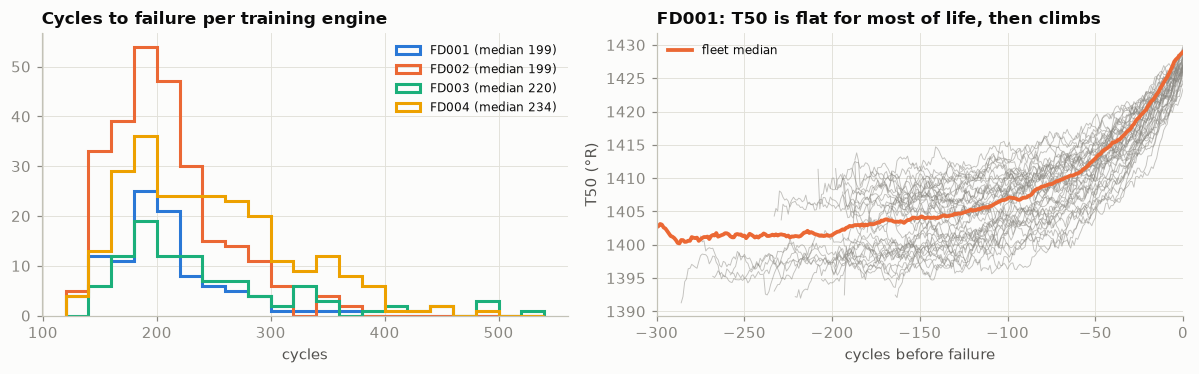

In [3]:
tr001 = cm[(cm.subset == TRAIN_SET) & (cm.part == "train")]
life = cm[cm.part == "train"].groupby(["subset", "engine"]).cycle.max()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
bins = np.arange(120, 560, 20)
for fd, color in zip(SUBSETS, SERIES):
    ax.hist(life[fd], bins=bins, histtype="step", lw=2, color=color, label=f"{fd} (median {life[fd].median():.0f})")
ax.set_title("Cycles to failure per training engine"); ax.set_xlabel("cycles"); ax.legend(fontsize=8)
ax = axes[1]
for e, d in list(tr001.groupby("engine"))[:40]:
    ax.plot(-d.rul, d.s4.rolling(10, min_periods=1).mean(), color=MUTED, lw=0.6, alpha=0.5)
med = tr001[tr001.rul <= 300].groupby("rul").s4.median().rolling(10, min_periods=1, center=True).mean()
ax.plot(-med.index, med.values, color=SERIES[1], lw=2.5, label="fleet median")
ax.set_xlim(-300, 0); ax.set_xlabel("cycles before failure"); ax.set_ylabel("T50 (°R)")
ax.set_title("FD001: T50 is flat for most of life, then climbs"); ax.legend(fontsize=8)
plt.tight_layout()

# sensor behaviour per subset: distinct values in training, and correlation with RUL
rows = []
for c in SENSORS:
    r = {"sensor": f"{c} · {SYM[c]}", "role": SENSOR_TABLE.role[c]}
    for fd in ["FD001", "FD003"]:
        d = cm[(cm.subset == fd) & (cm.part == "train")]
        r[f"distinct · {fd}"] = d[c].nunique()
        r[f"corr with RUL · {fd}"] = d[c].corr(d.rul) if d[c].nunique() > 1 else np.nan
    r["distinct · FD002"] = cm.loc[(cm.subset == "FD002") & (cm.part == "train"), c].nunique()
    rows.append(r)
sensor_look = pd.DataFrame(rows).set_index("sensor")
print("life to failure (cycles):", life.groupby("subset").agg(["min", "median", "max"]).to_dict("index"))
fmt(sensor_look, {"corr with RUL · FD001": "{:+.2f}", "corr with RUL · FD003": "{:+.2f}"})

T50 barely moves for most of a life and climbs in roughly the last hundred cycles: the signal exists late, which is why the target below is capped. The table holds two warnings. Seven FD001 sensors are constant or two-valued, yet all move in FD002, where they track the regime. And five sensors (P30, phi, BPR, W31, W32) flip sign or lose their correlation with RUL in FD003, because the fan fault moves them the other way: a model trained on one fault mode misreads the other.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · A remaining-life model, split by engine

*Part B · Given model · package `healthy_baseline`, `normalise`, `features`, `phm_score` and `scores` unchanged and reproduce the numbers (C2).*

Three decisions make this a C-MAPSS model rather than a generic regressor:

- **The target is capped** at `min(RUL, 125)`: the model learns "healthy" until wear shows, then counts down (the piecewise-linear target used since PHM08).
- **Features obey the as-of rule.** At cycle *t*, only cycles ≤ *t* of the same engine: each sensor's value and its mean, standard deviation and slope over the last `WINDOW` cycles, plus age. Sensors are first expressed as deviations from a **healthy baseline**: every engine's first `BASELINE_CYCLES` cycles, pooled per flight regime.
- **The split is by engine**, the independent unit (there is no calendar): 5-fold *group* cross-validation over the 100 training engines, then the official test files, scored once at each engine's last cycle.

Two metrics: **RMSE** in cycles, and the **PHM08 score**, summed over engines, which grows exponentially with the error and penalises a *late* prediction (the engine fails before we said) harder than an early one.

In [4]:
HEALTH = [c for c in SENSORS if tr001[c].nunique() > 2]      # rule: drop sensors constant (or two-valued) in the training fleet
print(f"{len(HEALTH)} health sensors kept: {[SYM[c] for c in HEALTH]}")

def healthy_baseline(d: pd.DataFrame, cols=None) -> pd.DataFrame:
    """Mean and std of each sensor per regime over every engine's first BASELINE_CYCLES cycles (no labels used)."""
    return d[d.cycle <= BASELINE_CYCLES].groupby("regime")[cols or HEALTH].agg(["mean", "std"])

def normalise(d: pd.DataFrame, base: pd.DataFrame, by_regime: bool = True) -> pd.DataFrame:
    """z-score against the healthy baseline; by_regime=False applies the first regime's statistics to every row."""
    reg = d.regime if by_regime else pd.Series(base.index[0], index=d.index)
    cols = base.columns.get_level_values(0).unique()
    return pd.DataFrame({c: (d[c] - reg.map(base[(c, "mean")])) / reg.map(base[(c, "std")]) for c in cols}, index=d.index)

def features(d: pd.DataFrame, Z: pd.DataFrame) -> pd.DataFrame:
    """As-of features: current value, rolling mean / std / slope over WINDOW past cycles of the same engine. d sorted by engine, cycle."""
    t = d.cycle.astype(float)
    cols = list(Z.columns)
    stack = pd.concat([Z, Z.mul(t, axis=0).add_suffix("_xt"), t.rename("t"), (t * t).rename("t2")], axis=1)
    roll = stack.groupby(d.engine.values, sort=False).rolling(WINDOW, min_periods=1)
    m = roll.mean().reset_index(level=0, drop=True)
    sd = Z.groupby(d.engine.values, sort=False).rolling(WINDOW, min_periods=2).std().reset_index(level=0, drop=True)
    var_t = (m["t2"] - m["t"] ** 2).replace(0, np.nan)
    X = {"cycle": d.cycle.values}
    for c in cols:
        X[c] = Z[c].values
        X[c + "_mean"] = m[c].values
        X[c + "_std"] = sd[c].values
        X[c + "_slope"] = ((m[c + "_xt"] - m[c] * m["t"]) / var_t).values
    return pd.DataFrame(X, index=d.index)

def phm_score(err):
    err = np.asarray(err, float)                    # err = predicted − true; late (err > 0) costs more
    return np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)

def scores(pred, true, name):
    e = np.asarray(pred) - np.asarray(true)
    return {"model": name, "RMSE": np.sqrt(np.mean(e ** 2)), "PHM score (sum)": phm_score(e).sum(),
            "PHM score / engine": phm_score(e).mean(), "late share": (e > 0).mean(), "bias (cycles)": e.mean()}

LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.7, reg_lambda=2.0, random_state=SEED, verbose=-1, n_jobs=1)

fd1 = cm[cm.subset == TRAIN_SET]
base1 = healthy_baseline(fd1[fd1.part == "train"])
t0 = time.time()
X1 = features(fd1, normalise(fd1, base1))
tr, te = (fd1.part == "train").values, (fd1.part == "test").values
y1 = np.minimum(fd1.rul.values, RUL_CAP)
groups = fd1.engine.values
is_last = (fd1.groupby("engine").cycle.transform("max") == fd1.cycle).values
print(f"{X1.shape[1]} features for {len(X1):,} cycles in {time.time()-t0:.1f}s")

oof = np.zeros(tr.sum())
for a, b in GroupKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X1[tr], y1[tr], groups[tr]):
    oof[b] = lgb.LGBMRegressor(**LGB_PARAMS).fit(X1[tr].iloc[a], y1[tr][a]).predict(X1[tr].iloc[b])
model = lgb.LGBMRegressor(**LGB_PARAMS).fit(X1[tr], y1[tr])
pred_te = model.predict(X1[te])
last_te = is_last[te]
y_te_last = fd1.rul.values[te][last_te]

mean_life = life[TRAIN_SET].mean()
naive = lambda d: np.clip(mean_life - d.cycle.values, 0, RUL_CAP)      # "every engine lives the fleet average"
rtr = fd1.rul.values[tr]; zone = rtr <= 50
res = []
for name, p_oof, p_te in [("fleet-average life (no model)", naive(fd1[tr]), naive(fd1[te])), ("LightGBM, rolling features", oof, pred_te)]:
    r = scores(p_te[last_te], y_te_last, name)
    r = {"model": name, "OOF RMSE (capped, all cycles)": np.sqrt(np.mean((p_oof - y1[tr]) ** 2)),
         "OOF RMSE (true RUL ≤ 50)": np.sqrt(np.mean((p_oof[zone] - rtr[zone]) ** 2)),
         "test RMSE": r["RMSE"], "test PHM score (sum)": r["PHM score (sum)"], "test late share": r["late share"]}
    res.append(r)
baseline_tbl = pd.DataFrame(res).set_index("model")
fmt(baseline_tbl, {c: "{:.1f}" for c in baseline_tbl.columns} | {"test PHM score (sum)": "{:,.0f}", "test late share": "{:.0%}"})

14 health sensors kept: ['T24', 'T30', 'T50', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'NRc', 'BPR', 'htBleed', 'W31', 'W32']


57 features for 33,727 cycles in 0.4s


,"OOF RMSE (capped, all cycles)",OOF RMSE (true RUL ≤ 50),test RMSE,test PHM score (sum),test late share
model,,,,,
fleet-average life (no model),30.6,30.8,36.8,"23,170",54%
"LightGBM, rolling features",12.3,7.1,13.2,238,59%


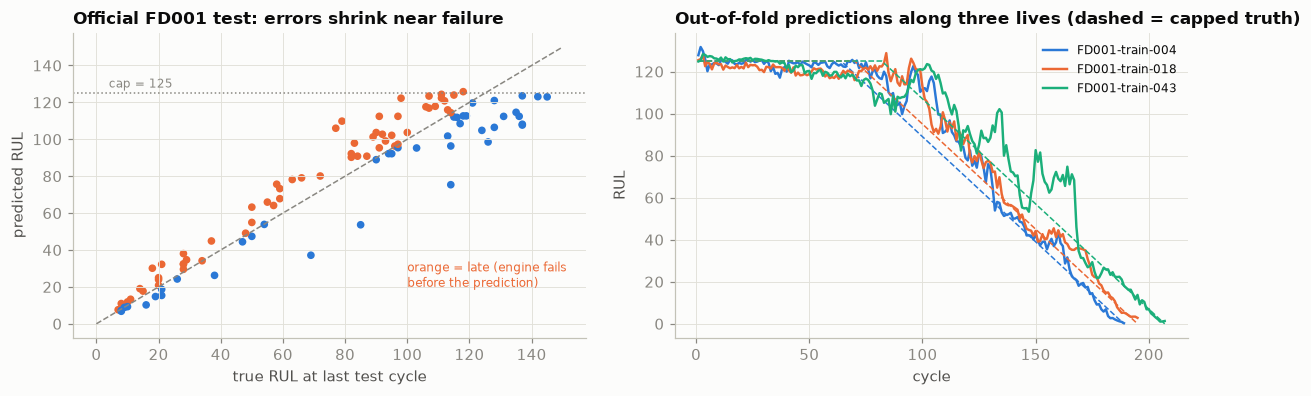

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
ax = axes[0]
err = pred_te[last_te] - y_te_last
ax.scatter(y_te_last, pred_te[last_te], s=16, c=np.where(err > 0, SERIES[1], SERIES[0]))
ax.plot([0, 150], [0, 150], color=MUTED, lw=1, ls="--"); ax.axhline(RUL_CAP, color=MUTED, lw=1, ls=":")
ax.text(4, RUL_CAP + 3, f"cap = {RUL_CAP}", color=MUTED, fontsize=8)
ax.text(100, 20, "orange = late (engine fails\nbefore the prediction)", color=SERIES[1], fontsize=8)
ax.set_xlabel("true RUL at last test cycle"); ax.set_ylabel("predicted RUL")
ax.set_title("Official FD001 test: errors shrink near failure")
ax = axes[1]
o1 = fd1[tr][["engine", "cycle", "rul"]].assign(pred=oof)
for e, color in zip(o1.engine.unique()[[3, 17, 42]], SERIES):
    d = o1[o1.engine == e]
    ax.plot(d.cycle, d.pred, color=color, lw=1.6, label=e)
    ax.plot(d.cycle, np.minimum(d.rul, RUL_CAP), color=color, lw=1, ls="--")
ax.set_xlabel("cycle"); ax.set_ylabel("RUL"); ax.legend(fontsize=8)
ax.set_title("Out-of-fold predictions along three lives (dashed = capped truth)")
plt.tight_layout()

On the official test files the model's RMSE is 13.2 cycles and its PHM score 238, against 36.8 and 23,170 for the rule that every engine lives the fleet average. Out of fold the error is 12.3 cycles against the capped target and 7.1 in the last 50 cycles of life, where decisions are made. Yet 59% of test predictions are late: squared error has no reason to prefer early, so the operating point must price late errors (task C3).

## 4 · The operating point: hangar slots, failures and wasted life

*Part B · Given model · package `simulate`, `policy_cost` and `fresh_fleet`; C3 asks you to own the costs and hangar slots.*

A prediction is not a decision. The planner's rule: **at each weekly review, list every engine whose predicted RUL ≤ T**; the hangar inducts at most `HANGAR_SLOTS_PER_WEEK`, lowest prediction first, and the rest keep flying. A failure before induction costs `COST_UNSCHEDULED_EUR`; an induction with life left costs `COST_WASTED_CYCLE_EUR` per remaining cycle. We replay the 100 training engines as a fleet (each entering service in a random week of the first 20) with their **out-of-fold** predictions, against today's rule: **fixed-age removal** at age A, under the same hangar.

,failures,wasted cycles / engine,cost / engine (k€),peak week due
"fixed age A = 150, 4 slots",17,45.0,118.5,16
"predicted RUL ≤ 50, 4 slots",2,21.8,38.7,22
"predicted RUL ≤ 15, unlimited hangar",0,9.7,14.6,8


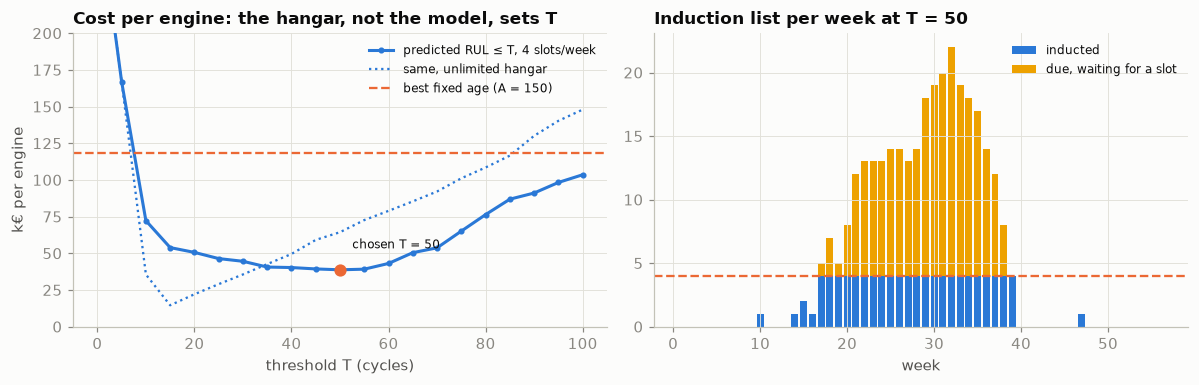

In [6]:
def simulate(frame: pd.DataFrame, entry: pd.Series, thr: float, slots=HANGAR_SLOTS_PER_WEEK):
    """Weekly reviews: induct engines with predicted RUL <= thr, at most `slots` a week (lowest prediction first).
    frame: engine, cycle, rul, pred (one row per cycle). Returns per-engine outcomes and per-week inductions / queue."""
    lives = frame.groupby("engine").cycle.max()
    engines, L = lives.index.values, lives.values
    P = frame[frame.cycle % CHECK_EVERY == 0].pivot(index="engine", columns="cycle", values="pred").reindex(engines).values
    start = entry.reindex(engines).values
    status, at = np.zeros(len(engines), int), np.full(len(engines), -1)    # 0 flying, 1 inducted, 2 failed
    weeks = []
    for w in range(1, int(start.max() + L.max() // CHECK_EVERY + 2)):
        c = (w - start) * CHECK_EVERY                                     # cycles flown at this review
        flying = (status == 0) & (c >= CHECK_EVERY)
        failed = flying & (c > L)
        status[failed], at[failed] = 2, L[failed]
        idx = np.flatnonzero(flying & ~failed)
        p = P[idx, c[idx] // CHECK_EVERY - 1]
        due = idx[p <= thr][np.argsort(p[p <= thr])]
        take = due[:slots] if slots else due
        status[take], at[take] = 1, c[take]
        weeks.append({"week": w, "inducted": len(take), "queued": len(due) - len(take), "failed": int(failed.sum())})
    out = pd.DataFrame({"engine": engines, "life": L, "status": status, "stop": at})
    out["wasted"] = np.where(out.status == 1, out.life - out.stop, 0)
    return out, pd.DataFrame(weeks).set_index("week")

def policy_cost(out):
    return {"failures": int((out.status == 2).sum()), "wasted cycles / engine": out.wasted.mean(),
            "cost / engine (k€)": (COST_UNSCHEDULED_EUR * (out.status == 2).sum() + COST_WASTED_CYCLE_EUR * out.wasted.sum()) / len(out) / 1e3}

hard_time = lambda frame, A: frame.assign(pred=np.where(frame.cycle >= A, 0.0, 1e9))
entry1 = pd.Series(np.random.default_rng(SEED).integers(0, ENTRY_WEEKS, o1.engine.nunique()), index=sorted(o1.engine.unique()))
THRESHOLDS, AGES = np.arange(0, 105, 5), np.arange(100, 260, 10)
curve = pd.DataFrame([{"T": T, **policy_cost(simulate(o1, entry1, T)[0])} for T in THRESHOLDS]).set_index("T")
curve_free = pd.DataFrame([{"T": T, **policy_cost(simulate(o1, entry1, T, slots=None)[0])} for T in THRESHOLDS]).set_index("T")
ages = pd.DataFrame([{"A": A, **policy_cost(simulate(hard_time(o1, A), entry1, 0)[0])} for A in AGES]).set_index("A")
THR = int(curve["cost / engine (k€)"].idxmin())
A_BEST = int(ages["cost / engine (k€)"].idxmin())
out_rul, wk_rul = simulate(o1, entry1, THR)
out_age, wk_age = simulate(hard_time(o1, A_BEST), entry1, 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(curve.index, curve["cost / engine (k€)"], "-o", ms=3, lw=2, color=SERIES[0], label=f"predicted RUL ≤ T, {HANGAR_SLOTS_PER_WEEK} slots/week")
ax.plot(curve_free.index, curve_free["cost / engine (k€)"], ":", lw=1.5, color=SERIES[0], label="same, unlimited hangar")
ax.axhline(ages["cost / engine (k€)"].min(), color=SERIES[1], lw=1.5, ls="--", label=f"best fixed age (A = {A_BEST})")
ax.plot([THR], [curve.loc[THR, "cost / engine (k€)"]], "o", color=SERIES[1], ms=7)
ax.annotate(f"chosen T = {THR}", (THR, curve.loc[THR, "cost / engine (k€)"]), xytext=(8, 14), textcoords="offset points", fontsize=8)
ax.set_ylim(0, 200); ax.set_xlabel("threshold T (cycles)"); ax.set_ylabel("k€ per engine")
ax.set_title("Cost per engine: the hangar, not the model, sets T"); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(wk_rul.index, wk_rul.inducted, color=SERIES[0], width=0.8, label="inducted")
ax.bar(wk_rul.index, wk_rul.queued, bottom=wk_rul.inducted, color=SERIES[3], width=0.8, label="due, waiting for a slot")
ax.axhline(HANGAR_SLOTS_PER_WEEK, color=SERIES[1], ls="--", lw=1.5)
ax.set_xlabel("week"); ax.set_title(f"Induction list per week at T = {THR}"); ax.legend(fontsize=8)
plt.tight_layout()

THR_FREE = int(curve_free["cost / engine (k€)"].idxmin())
out_free, wk_free = simulate(o1, entry1, THR_FREE, slots=None)
peak = lambda wk: (wk.inducted + wk.queued).max()
policy_tbl = pd.DataFrame({
    f"fixed age A = {A_BEST}, {HANGAR_SLOTS_PER_WEEK} slots": {**policy_cost(out_age), "peak week due": peak(wk_age)},
    f"predicted RUL ≤ {THR}, {HANGAR_SLOTS_PER_WEEK} slots": {**policy_cost(out_rul), "peak week due": peak(wk_rul)},
    f"predicted RUL ≤ {THR_FREE}, unlimited hangar": {**policy_cost(out_free), "peak week due": peak(wk_free)},
}).T
fmt(policy_tbl, {"failures": "{:.0f}", "wasted cycles / engine": "{:.1f}", "cost / engine (k€)": "{:.1f}", "peak week due": "{:.0f}"})

In [7]:
# T and A were both tuned on ONE calendar (entry1). Freeze them and replay fresh fleets: a new entry calendar per draw,
# with the same 100 engines or with the engines bootstrap-resampled. The saving is what the board question asks for.
by_engine = dict(tuple(o1.groupby("engine")))
engine_ids = np.array(sorted(by_engine))

def fresh_fleet(seed: int, resample: bool):
    r = np.random.default_rng(seed)
    pick = r.choice(engine_ids, len(engine_ids), replace=True) if resample else engine_ids
    names = [f"{e}#{i}" for i, e in enumerate(pick)]
    frame = pd.concat([by_engine[e].assign(engine=n) for e, n in zip(pick, names)], ignore_index=True)
    return frame, pd.Series(r.integers(0, ENTRY_WEEKS, len(pick)), index=names)

draws = [{"evaluation": "tuning calendar (in-sample)", "rule": policy_cost(out_rul)["cost / engine (k€)"],
          "age": policy_cost(out_age)["cost / engine (k€)"], "rule failures": policy_cost(out_rul)["failures"],
          "age failures": policy_cost(out_age)["failures"]}]
for resample in [False, True]:
    for k in range(N_EVAL_DRAWS):
        f, ent = fresh_fleet(SEED + 1000 + k, resample)
        c_rul, c_age = policy_cost(simulate(f, ent, THR)[0]), policy_cost(simulate(hard_time(f, A_BEST), ent, 0)[0])
        draws.append({"evaluation": f"{N_EVAL_DRAWS} fresh calendars" + (" + resampled engines" if resample else ", same engines"),
                      "rule": c_rul["cost / engine (k€)"], "age": c_age["cost / engine (k€)"],
                      "rule failures": c_rul["failures"], "age failures": c_age["failures"]})
draws = pd.DataFrame(draws)
draws["saving per 100 engines (€M)"] = (draws.age - draws.rule) * 100 / 1e3
spread = lambda s, f: f"{f.format(s.mean())} [{f.format(s.min())}–{f.format(s.max())}]" if len(s) > 1 else f.format(s.iloc[0])
robust_tbl = draws.groupby("evaluation", sort=False).agg(**{
    f"predicted RUL ≤ {THR} (k€/engine)": ("rule", lambda s: spread(s, "{:.1f}")),
    f"fixed age {A_BEST} (k€/engine)": ("age", lambda s: spread(s, "{:.1f}")),
    "saving per 100 engines (€M)": ("saving per 100 engines (€M)", lambda s: spread(s, "{:.1f}")),
    "failures (rule / fixed age)": ("rule failures", lambda s: f"{s.mean():.1f}"),
})
robust_tbl["failures (rule / fixed age)"] += " / " + draws.groupby("evaluation", sort=False)["age failures"].mean().map("{:.1f}".format)
fresh = draws[draws.evaluation != "tuning calendar (in-sample)"]
print(f"the prediction rule is cheaper in {(fresh.age > fresh.rule).sum()} of {len(fresh)} fresh draws (mean [min–max] shown)")
robust_tbl

the prediction rule is cheaper in 40 of 40 fresh draws (mean [min–max] shown)


,predicted RUL ≤ 50 (k€/engine),fixed age 150 (k€/engine),saving per 100 engines (€M),failures (rule / fixed age)
evaluation,,,,
tuning calendar (in-sample),38.7,118.5,8.0,2.0 / 17.0
"20 fresh calendars, same engines",46.7 [35.9–58.8],119.9 [110.2–133.2],7.3 [5.6–9.1],0.6 / 16.1
20 fresh calendars + resampled engines,46.7 [41.0–55.9],116.8 [102.3–136.2],7.0 [5.5–9.3],0.5 / 16.4


In [8]:
# The frozen threshold on the official test fleet: one review, with the true RUL revealed
snap = fd1[te][last_te][["engine", "cycle", "rul"]].assign(pred=pred_te[last_te])
due = snap.pred <= THR
critical = snap.rul < CHECK_EVERY                   # would fail before next week's review
print(f"official test fleet at its last cycle: {due.sum()} of {len(snap)} engines due at T = {THR} "
      f"(= {due.sum() / HANGAR_SLOTS_PER_WEEK:.0f} weeks of hangar slots)")
print(f"engines that would fail before the next review: {critical.sum()} · on the list: {(critical & due).sum()}")
print(f"due engines' true remaining life: median {snap.rul[due].median():.0f} cycles, "
      f"{(snap.rul[due] > 2 * THR).sum()} with more than {2 * THR} cycles left")
print(f"engines not due but with true RUL ≤ {THR}: {((~due) & (snap.rul <= THR)).sum()}")

official test fleet at its last cycle: 32 of 100 engines due at T = 50 (= 8 weeks of hangar slots)
engines that would fail before the next review: 5 · on the list: 5
due engines' true remaining life: median 20 cycles, 0 with more than 100 cycles left
engines not due but with true RUL ≤ 50: 2


Three readings. **The model's value is the gap to fixed-age removal:** on the calendar both rules were tuned on, €118.5k per engine at the best age (A = 150: 17 failures) against €38.7k with predicted RUL ≤ 50 (2 failures), or €8.0M per 100 engines. That figure is in-sample. Frozen and replayed on 20 fresh calendars with resampled engines, the saving averages €7.0M (range €5.5M–€9.3M), and the prediction rule wins all 40 fresh draws; the costs are assumptions. **The hangar, not the model, sets T:** with unlimited slots the best threshold is 15 cycles and the cost €14.6k; with four, the list peaks at 22 engines due in a week, so engines must be listed earlier for the queue to drain before they fail — a scheduling problem in disguise (task C3). **On the official test fleet** the frozen rule lists 32 of 100 engines at once (the benchmark cuts every engine at the same instant), but all 5 that would fail before the next review are on it, and the median listed engine has 20 cycles left.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test, and `psi` with the range check feeds monitoring (C5).*

Five things a careless version of this notebook would have done, each measured: naive number against honest number.

**Trap 1 — the row-level split.** Shuffle the 20,631 training cycles into folds and neighbouring cycles of one engine land on both sides; their rolling features are nearly identical, so the model interpolates instead of predicting.

**Trap 2 — the uncapped target.** Train on the raw RUL and score every cycle against the raw RUL, and the uncapped model *wins*: it is rewarded for guessing how long a healthy engine will last, which nobody can know. Score where the decision is made and the verdict flips.

In [9]:
oof_rows = np.zeros(tr.sum())
for a, b in KFold(N_FOLDS, shuffle=True, random_state=SEED).split(X1[tr]):
    oof_rows[b] = lgb.LGBMRegressor(**LGB_PARAMS).fit(X1[tr].iloc[a], y1[tr][a]).predict(X1[tr].iloc[b])
rmse = lambda p, y: float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))
traps = [{"trap": "1 · row-level split", "metric": "OOF RMSE, FD001 train",
          "naive": rmse(oof_rows, y1[tr]), "honest": rmse(oof, y1[tr])}]

model_uncapped = lgb.LGBMRegressor(**LGB_PARAMS).fit(X1[tr], fd1.rul.values[tr])
pu = model_uncapped.predict(X1[te]); rte = fd1.rul.values[te]
print(f"Trap 2 · all test cycles vs raw RUL — uncapped model RMSE {rmse(pu, rte):.1f} · capped model {rmse(pred_te, rte):.1f}  ← the naive verdict")
s_unc, s_cap = scores(pu[last_te], y_te_last, "uncapped"), scores(pred_te[last_te], y_te_last, "capped")
print(f"Trap 2 · official test (last cycle) — uncapped RMSE {s_unc['RMSE']:.1f}, PHM {s_unc['PHM score (sum)']:,.0f}, "
      f"late {s_unc['late share']:.0%} · capped RMSE {s_cap['RMSE']:.1f}, PHM {s_cap['PHM score (sum)']:,.0f}, late {s_cap['late share']:.0%}")
traps.append({"trap": "2 · uncapped RUL target", "metric": "test RMSE, last cycle", "naive": s_unc["RMSE"], "honest": s_cap["RMSE"]})

Trap 2 · all test cycles vs raw RUL — uncapped model RMSE 41.4 · capped model 55.7  ← the naive verdict
Trap 2 · official test (last cycle) — uncapped RMSE 23.8, PHM 4,928, late 73% · capped RMSE 13.2, PHM 238, late 59%


**Trap 3 — the end of a test trajectory is not a failure.** The test files look like 100 more training engines. Label their last cycle as the failure and every label is short by the RUL file's offset; the model learns that engines die early.

**Trap 4 — constant sensors.** Seven FD001 sensors never move (or take two values). They cost the tree nothing, but they are the channels that encode the regime when FD002 arrives, and Task 02's PSI cannot see them move.

**Trap 5 — one scaler across six regimes.** Train on FD002 with one global scaler (or raw sensors plus the settings) instead of a baseline per regime.

In [10]:
wrong = (fd1[te].groupby("engine").cycle.transform("max") - fd1[te].cycle).values      # "the last cycle is the failure"
print(f"Trap 3 · end-as-failure labels are short by {np.mean(rte - wrong):.0f} cycles on average (by {y_te_last.mean():.0f} at the last cycle)")
held = np.isin(groups[tr], np.random.default_rng(SEED).choice(np.unique(groups[tr]), 20, replace=False))
m_clean = lgb.LGBMRegressor(**LGB_PARAMS).fit(X1[tr][~held], y1[tr][~held])
m_aug = lgb.LGBMRegressor(**LGB_PARAMS).fit(pd.concat([X1[tr][~held], X1[te]]), np.r_[y1[tr][~held], np.minimum(wrong, RUL_CAP)])
p_clean, p_aug = m_clean.predict(X1[tr][held]), m_aug.predict(X1[tr][held])
print(f"Trap 3 · 20 held-out training engines — clean: RMSE {rmse(p_clean, y1[tr][held]):.1f}, bias {np.mean(p_clean - y1[tr][held]):+.1f} · "
      f"with mislabelled test engines: RMSE {rmse(p_aug, y1[tr][held]):.1f}, bias {np.mean(p_aug - y1[tr][held]):+.1f}")
traps.append({"trap": "3 · test end used as failure", "metric": "RMSE, 20 held-out engines", "naive": rmse(p_aug, y1[tr][held]),
              "honest": rmse(p_clean, y1[tr][held])})

def psi(ref, cur, bins=10):                       # Task 02's PSI, unchanged
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

base_all = healthy_baseline(fd1[fd1.part == "train"], cols=SENSORS)          # keep every sensor, constant or not
X_all = features(fd1, normalise(fd1, base_all))
p_all = lgb.LGBMRegressor(**LGB_PARAMS).fit(X_all[tr], y1[tr]).predict(X_all[te])
fd2 = cm[cm.subset == SHIFT_SET]
t2_ref, t2_new = tr001.s1.values, fd2.s1.values
outside = (t2_new < t2_ref.min()) | (t2_new > t2_ref.max())
print(f"Trap 4 · all 21 sensors: test RMSE {rmse(p_all[last_te], y_te_last):.1f} vs {s_cap['RMSE']:.1f} with {len(HEALTH)} · "
      f"{X_all.isna().mean().mean():.0%} of feature values become NaN (0/0 from zero-variance z-scores)")
print(f"Trap 4 · FD001 → FD002, T2: PSI {psi(t2_ref, t2_new):.2f} · share of FD002 cycles outside the T2 range seen in training {outside.mean():.0%}")
traps.append({"trap": "4 · constant sensors kept (model)", "metric": "test RMSE, last cycle", "naive": rmse(p_all[last_te], y_te_last),
              "honest": s_cap["RMSE"]})
display(pd.DataFrame({"Trap 4 · what the monitor sees for T2, FD001 → FD002": [
    "Task 02's PSI (quantile bins on the FD001 reference)", "share of FD002 cycles outside T2's FD001 range"],
    "value": [f"{psi(t2_ref, t2_new):.2f}", f"{outside.mean():.0%}"]}).set_index("Trap 4 · what the monitor sees for T2, FD001 → FD002"))

tr2, te2 = (fd2.part == "train").values, (fd2.part == "test").values
y2 = np.minimum(fd2.rul.values, RUL_CAP)
last2 = (fd2.groupby("engine").cycle.transform("max") == fd2.cycle).values[te2]
y2_last = fd2.rul.values[te2][last2]
base2 = healthy_baseline(fd2[tr2])
X2 = features(fd2, normalise(fd2, base2))                                       # per-regime healthy baseline
glob = fd2.loc[tr2, HEALTH].agg(["mean", "std"])
X2_glob = features(fd2, (fd2[HEALTH] - glob.loc["mean"]) / glob.loc["std"])     # one scaler for all regimes
X2_raw = features(fd2, fd2[HEALTH].astype(float)).assign(setting1=fd2.setting1.values, setting2=fd2.setting2.values,
                                                         setting3=fd2.setting3.values)
fd2_models, fd2_scores = {}, []
for name, X in [("per-regime baseline", X2), ("one global scaler", X2_glob), ("raw sensors + settings", X2_raw)]:
    fd2_models[name] = lgb.LGBMRegressor(**LGB_PARAMS).fit(X[tr2], y2[tr2])
    fd2_scores.append(scores(fd2_models[name].predict(X[te2])[last2], y2_last, f"FD002-trained · {name}"))
fd2_tbl = pd.DataFrame(fd2_scores).set_index("model")
SCORE_FMT = {"RMSE": "{:.1f}", "PHM score (sum)": "{:,.0f}", "PHM score / engine": "{:.1f}", "late share": "{:.0%}", "bias (cycles)": "{:+.1f}"}
display(fmt(fd2_tbl, SCORE_FMT))
traps.append({"trap": "5 · one scaler across regimes", "metric": "FD002 test RMSE, last cycle",
              "naive": fd2_tbl.RMSE.iloc[1], "honest": fd2_tbl.RMSE.iloc[0]})
fmt(pd.DataFrame(traps).set_index("trap"), {"naive": "{:.2f}", "honest": "{:.2f}"})

Trap 3 · end-as-failure labels are short by 65 cycles on average (by 76 at the last cycle)


Trap 3 · 20 held-out training engines — clean: RMSE 12.5, bias -0.7 · with mislabelled test engines: RMSE 23.7, bias -15.8


Trap 4 · all 21 sensors: test RMSE 13.0 vs 13.2 with 14 · 25% of feature values become NaN (0/0 from zero-variance z-scores)
Trap 4 · FD001 → FD002, T2: PSI 0.00 · share of FD002 cycles outside the T2 range seen in training 85%


,value
"Trap 4 · what the monitor sees for T2, FD001 → FD002",
Task 02's PSI (quantile bins on the FD001 reference),0.00
share of FD002 cycles outside T2's FD001 range,85%


,RMSE,PHM score (sum),PHM score / engine,late share,bias (cycles)
model,,,,,
FD002-trained · per-regime baseline,25.6,"7,732",29.9,41%,-7.9
FD002-trained · one global scaler,27.7,"8,885",34.3,44%,-8.0
FD002-trained · raw sensors + settings,27.8,"8,628",33.3,43%,-7.8


,metric,naive,honest
trap,,,
1 · row-level split,"OOF RMSE, FD001 train",6.18,12.33
2 · uncapped RUL target,"test RMSE, last cycle",23.77,13.17
3 · test end used as failure,"RMSE, 20 held-out engines",23.70,12.55
4 · constant sensors kept (model),"test RMSE, last cycle",12.97,13.17
5 · one scaler across regimes,"FD002 test RMSE, last cycle",27.67,25.62


Read the table row by row. The row split halves the error (6.2 against 12.3). The uncapped model wins on all cycles (41.4 against 55.7) and loses at the decision point (23.8 against 13.2, 73% of predictions late, PHM 4,928 against 238). The mislabelled test engines double the error and bias predictions 16 cycles early: about €24k of wasted life per engine. Keeping the constant sensors changes nothing for the tree (13.0 against 13.2); the damage is to the monitor (the separate Trap 4 table): PSI reads 0.00 on T2 while 85% of FD002 cycles lie outside its training range, because a quantile-binned PSI over a constant reference has one bin. Check fixed channels against their range. One global scaler on FD002 costs 2.1 cycles (27.7 against 25.6); the real bill comes when the model has only seen one regime.

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: a six-regime fleet, and an induction list that goes quiet

*Part C · Productionise · what your monitoring plan must catch; reuse `weekly_rows` (C5).*

The planned shift: the airline adds engines on a new route network with six flight regimes (FD002). The FD001 model, its scaler and its threshold are frozen and pointed at the new fleet. First, what a regime does to a sensor compared with what wear does.

T50 over a life (FD001, last 10 cycles vs first 30): +24.6 °R · T50 across FD002's regimes: 1050–1409 °R (359 °R)


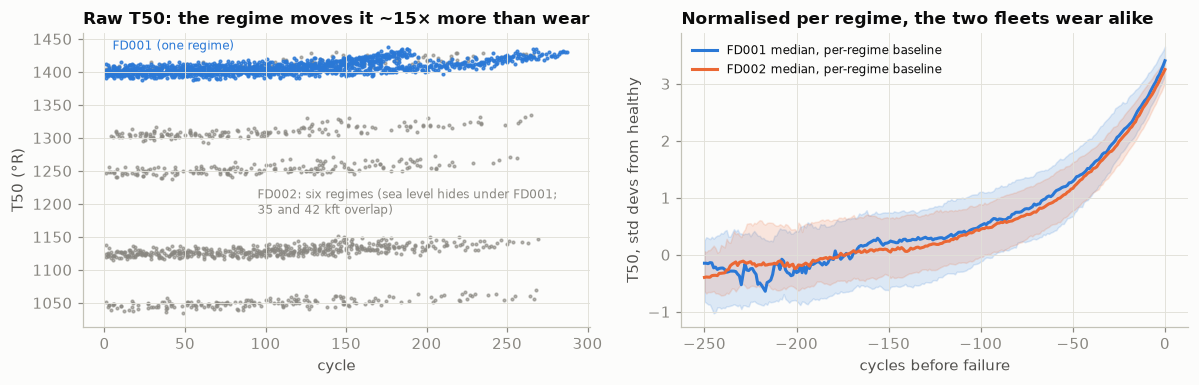

In [11]:
fd2_tr = fd2[tr2]
z1 = normalise(tr001, base1).s4.groupby(tr001.engine.values).transform(lambda s: s.rolling(WINDOW, min_periods=1).mean())
z2 = normalise(fd2_tr, base2).s4.groupby(fd2_tr.engine.values).transform(lambda s: s.rolling(WINDOW, min_periods=1).mean())
drift_life = tr001.loc[tr001.rul < 10, "s4"].mean() - tr001.loc[tr001.cycle <= BASELINE_CYCLES, "s4"].mean()
regime_means = fd2_tr.groupby("regime").s4.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for e, d in list(fd2_tr.groupby("engine"))[:6]:
    ax.scatter(d.cycle, d.s4, s=3, color=MUTED, alpha=0.6)
for e, d in list(tr001.groupby("engine"))[:6]:
    ax.scatter(d.cycle, d.s4, s=3, color=SERIES[0], alpha=0.8)
ax.text(5, regime_means.max() + 25, "FD001 (one regime)", color=SERIES[0], fontsize=8)
ax.text(95, 1185, "FD002: six regimes (sea level hides under FD001;\n35 and 42 kft overlap)", color=MUTED, fontsize=8)
ax.set_xlabel("cycle"); ax.set_ylabel("T50 (°R)"); ax.set_title("Raw T50: the regime moves it ~15× more than wear")
ax = axes[1]
for z, d, lab_, color in [(z1, tr001, "FD001", SERIES[0]), (z2, fd2_tr, "FD002", SERIES[1])]:
    g = pd.DataFrame({"rul": d.rul.values, "z": z.values}).query("rul <= 250").groupby("rul").z
    ax.fill_between(-g.median().index, g.quantile(0.25), g.quantile(0.75), color=color, alpha=0.15)
    ax.plot(-g.median().index, g.median(), color=color, lw=2, label=f"{lab_} median, per-regime baseline")
ax.set_xlabel("cycles before failure"); ax.set_ylabel("T50, std devs from healthy")
ax.set_title("Normalised per regime, the two fleets wear alike"); ax.legend(fontsize=8)
plt.tight_layout()
print(f"T50 over a life (FD001, last 10 cycles vs first {BASELINE_CYCLES}): {drift_life:+.1f} °R · "
      f"T50 across FD002's regimes: {regime_means.min():.0f}–{regime_means.max():.0f} °R ({regime_means.max() - regime_means.min():.0f} °R)")

cycles outside the training regimes: 85% from week 1 · PSI of predicted RUL, first 40 cycles of life vs FD001 validation: frozen 7.51, per-regime 0.53


,failures,wasted cycles / engine,cost / engine (k€),peak week due,RMSE (true RUL ≤ 125)
FD001 fleet (expected),2,21.8,38.7,22,13.4
frozen,99,0.6,298.0,1,37.2
fixed,10,20.9,61.4,22,17.1


,RMSE,PHM score (sum),PHM score / engine,late share,bias (cycles)
model,,,,,
FD001 model · frozen FD001 scaler,46.8,"71,939",277.8,53%,+1.9
FD001 model · per-regime baseline (no labels),28.4,"10,878",42.0,48%,-8.3
retrained on FD002 failures · per-regime,25.6,"7,732",29.9,41%,-7.9


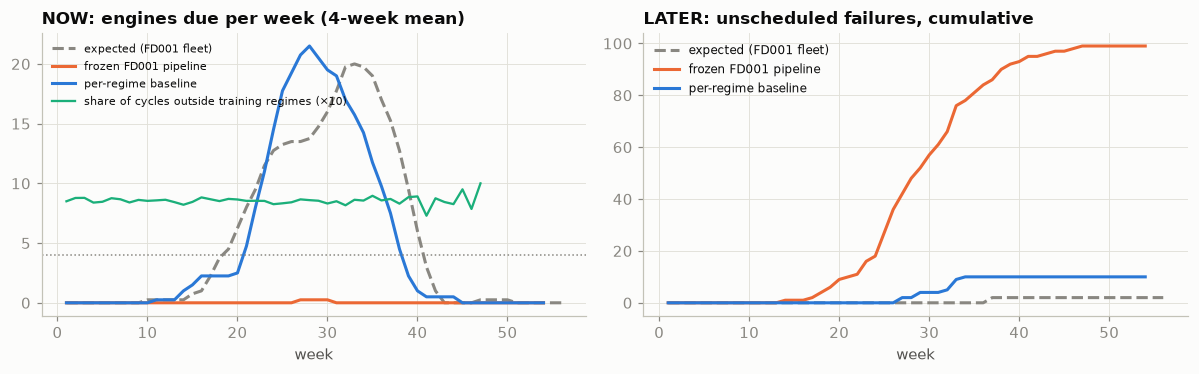

In [12]:
# Replay 100 FD002 engines on the same planning calendar, scored by the FROZEN FD001 pipeline and by the
# same model behind a per-regime baseline (estimated on the other 160 FD002 engines' first cycles; no failure labels)
rng = np.random.default_rng(SEED)
stream_ids = np.sort(rng.choice(fd2_tr.engine.unique(), STREAM_ENGINES, replace=False))
st = fd2_tr[fd2_tr.engine.isin(stream_ids)]
base_new = healthy_baseline(fd2_tr[~fd2_tr.engine.isin(stream_ids)])
st = st.assign(pred_frozen=model.predict(features(st, normalise(st, base1, by_regime=False))),
               pred_fixed=model.predict(features(st, normalise(st, base_new))))
entry2 = pd.Series(np.random.default_rng(SEED + 1).integers(0, ENTRY_WEEKS, STREAM_ENGINES), index=stream_ids)
runs = {"FD001 fleet (expected)": simulate(o1, entry1, THR)}
for k in ["frozen", "fixed"]:
    runs[k] = simulate(st[["engine", "cycle", "rul"]].assign(pred=st[f"pred_{k}"].values), entry2, THR)

def weekly_rows(frame, entry, out):
    """Cycles actually flown each week (engines stop flying once inducted or failed)."""
    o = out.set_index("engine")
    stop = o.stop.where(o.status > 0, np.inf)
    f = frame[frame.cycle <= frame.engine.map(stop)]
    return f.assign(week=f.engine.map(entry) + (f.cycle - 1) // CHECK_EVERY + 1)

wf = weekly_rows(st, entry2, runs["frozen"][0])
envelope = wf.groupby("week").regime.apply(lambda r: (r != 0).mean())
young = lambda f: f[f.cycle <= 4 * CHECK_EVERY]
psi_frozen = psi(young(o1).pred, young(st).pred_frozen)
psi_fixed = psi(young(o1).pred, young(st).pred_fixed)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
for (k, lab_), color, ls in zip([("FD001 fleet (expected)", "expected (FD001 fleet)"), ("frozen", "frozen FD001 pipeline"),
                                 ("fixed", "per-regime baseline")], [MUTED, SERIES[1], SERIES[0]], ["--", "-", "-"]):
    wk = runs[k][1]
    ax.plot(wk.index, (wk.inducted + wk.queued).rolling(4, min_periods=1).mean(), ls=ls, lw=2, color=color, label=lab_)
ax.plot(envelope.index, envelope * 10, color=SERIES[2], lw=1.5, label="share of cycles outside training regimes (×10)")
ax.axhline(HANGAR_SLOTS_PER_WEEK, color=MUTED, lw=1, ls=":")
ax.set_xlabel("week"); ax.set_title("NOW: engines due per week (4-week mean)"); ax.legend(fontsize=7.5)
ax = axes[1]
for (k, lab_), color, ls in zip([("FD001 fleet (expected)", "expected (FD001 fleet)"), ("frozen", "frozen FD001 pipeline"),
                                 ("fixed", "per-regime baseline")], [MUTED, SERIES[1], SERIES[0]], ["--", "-", "-"]):
    wk = runs[k][1]
    ax.plot(wk.index, wk.failed.cumsum(), ls=ls, lw=2, color=color, label=lab_)
ax.set_xlabel("week"); ax.set_title("LATER: unscheduled failures, cumulative"); ax.legend(fontsize=8)
plt.tight_layout()

zone_st = st.rul <= RUL_CAP
stream_tbl = pd.DataFrame({k: {**policy_cost(runs[k][0]), "peak week due": peak(runs[k][1]),
                               "RMSE (true RUL ≤ 125)": (rmse(o1.pred[o1.rul <= RUL_CAP], o1.rul[o1.rul <= RUL_CAP]) if k.startswith("FD001")
                                                         else rmse(st[f"pred_{k}"][zone_st], st.rul[zone_st]))} for k in runs}).T
print(f"cycles outside the training regimes: {(st.regime != 0).mean():.0%} from week 1 · "
      f"PSI of predicted RUL, first {4 * CHECK_EVERY} cycles of life vs FD001 validation: frozen {psi_frozen:.2f}, per-regime {psi_fixed:.2f}")
display(fmt(stream_tbl, {"failures": "{:.0f}", "wasted cycles / engine": "{:.1f}", "cost / engine (k€)": "{:.1f}",
                         "peak week due": "{:.0f}", "RMSE (true RUL ≤ 125)": "{:.1f}"}))

# the same comparison on FD002's official test files, plus the retrained ceiling
shift_tbl = pd.DataFrame([
    scores(model.predict(features(fd2[te2], normalise(fd2[te2], base1, by_regime=False)))[last2], y2_last, "FD001 model · frozen FD001 scaler"),
    scores(model.predict(X2[te2])[last2], y2_last, "FD001 model · per-regime baseline (no labels)"),
    scores(fd2_models["per-regime baseline"].predict(X2[te2])[last2], y2_last, "retrained on FD002 failures · per-regime"),
]).set_index("model")
fmt(shift_tbl, SCORE_FMT)

This is Task 02's silent failure, in a hangar. The frozen pipeline neither crashes nor floods the planner: it goes **quiet**. The list peaks at one engine due in a week against 22 expected, and 99 of 100 engines fail in service: €298k per engine against €38.7k on its own fleet. Nobody is alarmed by an empty induction list. Two signals were there from week one: 85% of cycles came from regimes the model had never seen (a contract check against the knowledge layer), and the PSI of predicted RUL on young engines was 7.5. The labels, failures, arrive weeks later.

The fix needs no labels. A healthy baseline per regime, estimated from other FD002 engines' first cycles, cuts FD002 test RMSE from 46.8 to 28.4 and the stream's cost to €61.4k (10 failures); retraining on FD002's failures reaches 25.6. The left figure is why: wear moves T50 by 25 °R over a life, the regime by 359 °R.

For the monitoring plan (task C5): a regime-envelope check on every cycle; engines due per week against an expected range (too few is an alarm too); retraining on a new regime or new failures. Note that a good policy removes engines before they fail, so most true lives are never observed (task E4).

## 7 · The knowledge layer, and what the technician's assistant is given

*Part C · Productionise · in Part C to keep the parts contiguous; package `build_kb`, `expand`, `retrieve` and `assemble_context` for E1's ablation and S1.*

The tables used since Section 1 are knowledge, and Sessions 07–09 treat knowledge as an artefact: designed from competency questions, built by code, validated with SHACL, versioned. Three questions drive this one: *which sensors observe the component a fault mode degrades?*, *which sensors are set by the regime or the controller?*, and *which fleets need per-regime normalisation?*

In [13]:
CM = Namespace("http://example.org/cmapss#")
README_ENGINES = {"FD001": (100, 100), "FD002": (260, 259), "FD003": (100, 100), "FD004": (248, 249)}   # (train, test) as the readme states
FAULT_MODES = {"HPCDegradation": ("HPC degradation", "HPC"), "FanDegradation": ("Fan degradation", "Fan")}
SUBSET_FAULTS = {"FD001": ["HPCDegradation"], "FD002": ["HPCDegradation"], "FD003": ["HPCDegradation", "FanDegradation"],
                 "FD004": ["HPCDegradation", "FanDegradation"]}
ROLE_CLASS = {"health": CM.HealthSensor, "condition": CM.RegimeSensor, "control": CM.ControlSensor}

def build_kb(engine_counts) -> Graph:
    g = Graph(); g.bind("cm", CM)
    for cls in ["HealthSensor", "RegimeSensor", "ControlSensor"]:
        g.add((CM[cls], RDFS.subClassOf, CM.Sensor))
    for comp in ["Fan", "LPC", "HPC", "Burner", "HPT", "LPT"]:
        g.add((CM[comp], RDF.type, CM.Component)); g.add((CM[comp], RDFS.label, Literal(comp)))
    for col, r in SENSOR_TABLE.iterrows():
        s = CM[col]
        g.add((s, RDF.type, ROLE_CLASS[r.role])); g.add((s, CM.column, Literal(col))); g.add((s, CM.symbol, Literal(r.symbol)))
        g.add((s, RDFS.comment, Literal(r.description))); g.add((s, CM.unit, Literal(r.unit)))
        for comp in filter(None, r.observes.split(";")):
            g.add((s, CM.observes, CM[comp]))
    for i, r in REGIMES.iterrows():
        n = CM[f"regime{i}"]
        g.add((n, RDF.type, CM.FlightRegime))
        for p, v in [("altitudeKft", r.altitude_kft), ("mach", r.mach), ("tra", r.tra)]:
            g.add((n, CM[p], Literal(f"{float(v):g}", datatype=XSD.decimal)))
    for k, (label, comp) in FAULT_MODES.items():
        g.add((CM[k], RDF.type, CM.FaultMode)); g.add((CM[k], RDFS.label, Literal(label))); g.add((CM[k], CM.affects, CM[comp]))
    for fd, (n_tr, n_te) in engine_counts.items():
        n = CM[fd]
        g.add((n, RDF.type, CM.SubDataset))
        g.add((n, CM.trainEngines, Literal(n_tr, datatype=XSD.integer))); g.add((n, CM.testEngines, Literal(n_te, datatype=XSD.integer)))
        for i in (range(6) if fd in ("FD002", "FD004") else [0]):
            g.add((n, CM.hasRegime, CM[f"regime{i}"]))
        for f in SUBSET_FAULTS[fd]:
            g.add((n, CM.hasFaultMode, CM[f]))
    return g

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix cm: <http://example.org/cmapss#> .
cm:SensorShape a sh:NodeShape ; sh:targetClass cm:Sensor ;
  sh:property [ sh:path cm:column ; sh:minCount 1 ; sh:maxCount 1 ; sh:pattern "^s[0-9]+$" ] ;
  sh:property [ sh:path cm:symbol ; sh:minCount 1 ; sh:maxCount 1 ] .
cm:HealthSensorShape a sh:NodeShape ; sh:targetClass cm:HealthSensor ;
  sh:property [ sh:path cm:observes ; sh:minCount 1 ; sh:class cm:Component ] .
cm:FaultModeShape a sh:NodeShape ; sh:targetClass cm:FaultMode ;
  sh:property [ sh:path cm:affects ; sh:minCount 1 ; sh:maxCount 1 ; sh:class cm:Component ] .
cm:RegimeShape a sh:NodeShape ; sh:targetClass cm:FlightRegime ;
  sh:property [ sh:path cm:altitudeKft ; sh:datatype xsd:decimal ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cm:mach ; sh:datatype xsd:decimal ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path cm:tra ; sh:datatype xsd:decimal ; sh:minCount 1 ; sh:maxCount 1 ] .
cm:SubDatasetShape a sh:NodeShape ; sh:targetClass cm:SubDataset ;
  sh:property [ sh:path cm:hasRegime ; sh:minCount 1 ; sh:class cm:FlightRegime ] ;
  sh:property [ sh:path cm:hasFaultMode ; sh:minCount 1 ; sh:class cm:FaultMode ] ;
  sh:property [ sh:path cm:trainEngines ; sh:datatype xsd:integer ; sh:minCount 1 ; sh:maxCount 1 ] .
"""
shapes = Graph().parse(data=SHAPES, format="turtle")
kb = build_kb(README_ENGINES)
ok, _, _ = shacl_validate(kb, shacl_graph=shapes)
broken = Graph() + kb; broken.remove((CM.s3, CM.observes, None))      # a health sensor that observes nothing
ok_broken, vg, _ = shacl_validate(broken, shacl_graph=shapes)
print(f"KB v1.0: {len(kb)} triples · SHACL conforms: {ok} · with T30's component link removed: conforms {ok_broken}, "
      f"{len(list(vg.subjects(RDF.type, rdflib.URIRef('http://www.w3.org/ns/shacl#ValidationResult'))))} violation")

# a consistency check the CI runs: the KB against the data it describes
in_data = cm.groupby(["subset", "part"]).engine.nunique().unstack()
for fd in SUBSETS:
    kb_tr = int(kb.value(CM[fd], CM.trainEngines)); kb_te = int(kb.value(CM[fd], CM.testEngines))
    if (kb_tr, kb_te) != (in_data.loc[fd, "train"], in_data.loc[fd, "test"]):
        print(f"  {fd}: readme says {kb_tr} train / {kb_te} test engines, files hold {in_data.loc[fd, 'train']} / {in_data.loc[fd, 'test']} → corrected in KB v1.1")
kb = build_kb({fd: (int(in_data.loc[fd, "train"]), int(in_data.loc[fd, "test"])) for fd in SUBSETS})

CQ = {
    "CQ1 · sensors on the component each fault mode degrades": """SELECT ?fault (GROUP_CONCAT(?sym; separator=", ") AS ?answer)
        WHERE { ?f a cm:FaultMode ; rdfs:label ?fault ; cm:affects ?c . ?s a cm:HealthSensor ;
                cm:observes ?c ; cm:symbol ?sym } GROUP BY ?fault""",
    "CQ2 · sensors set by the regime or the controller": """SELECT ?kind (GROUP_CONCAT(?sym; separator=", ") AS ?answer)
        WHERE { VALUES ?cls { cm:RegimeSensor cm:ControlSensor } ?s a ?cls ; cm:symbol ?sym .
                BIND(STRAFTER(STR(?cls), "#") AS ?kind) } GROUP BY ?kind""",
    "CQ3 · fleets needing per-regime normalisation": """SELECT ?fd (GROUP_CONCAT(DISTINCT ?fl; separator=" + ") AS ?answer)
        WHERE { ?d a cm:SubDataset ; cm:hasFaultMode/rdfs:label ?fl . BIND(STRAFTER(STR(?d), "#") AS ?fd)
                { SELECT ?d (COUNT(?r) AS ?n) WHERE { ?d cm:hasRegime ?r } GROUP BY ?d } FILTER(?n > 1) }
        GROUP BY ?fd ORDER BY ?fd""",
}
for q, sparql in CQ.items():
    print(q)
    for row in kb.query(sparql, initNs={"cm": CM, "rdfs": RDFS}):
        print(f"   {row[0]}: {row[1]}")

KB v1.0: 202 triples · SHACL conforms: True · with T30's component link removed: conforms False, 1 violation
  FD004: readme says 248 train / 249 test engines, files hold 249 / 248 → corrected in KB v1.1
CQ1 · sensors on the component each fault mode degrades
   HPC degradation: T30, P30, Nc, Ps30, phi, NRc, htBleed
   Fan degradation: P15, Nf, NRf, BPR
CQ2 · sensors set by the regime or the controller
   RegimeSensor: T2, P2
   ControlSensor: Nf_dmd, PCNfR_dmd
CQ3 · fleets needing per-regime normalisation
   FD002: HPC degradation
   FD004: HPC degradation + Fan degradation


The layer earns its keep before any model uses it: the consistency check catches the readme's swapped FD004 counts, and SHACL refuses a health sensor that observes no component. CQ1 becomes the fault-mode context below, CQ2 the sensors never to normalise per regime (they *are* the regime), CQ3 the routing rule for normalisation.

**The ablation (task E1 starts here).** On FD004 — six regimes *and* two fault modes, 248 official test engines — the same learner with three levels of graph context: **A** none (raw sensors); **B** + regime context (the per-regime baseline and the regime id); **C** + fault-mode context (per fault mode, the mean deviation of the sensors CQ1 returns, and the running evidence that the fan rather than the compressor is wearing). A paired bootstrap over test engines gives each step's uncertainty.

In [14]:
fd4 = cm[cm.subset == KB_SET]
tr4, te4 = (fd4.part == "train").values, (fd4.part == "test").values
last4 = (fd4.groupby("engine").cycle.transform("max") == fd4.cycle).values[te4]
y4_last = fd4.rul.values[te4][last4]
observers = {}
for row in kb.query("""SELECT ?fault ?col WHERE { ?f a cm:FaultMode ; rdfs:label ?fault ; cm:affects ?c . ?s a cm:HealthSensor ;
                       cm:observes ?c ; cm:column ?col }""", initNs={"cm": CM, "rdfs": RDFS}):
    if str(row[1]) in HEALTH:
        observers.setdefault(str(row[0]), []).append(str(row[1]))
Z4 = normalise(fd4, healthy_baseline(fd4[tr4]))
sign = {c: np.sign(np.corrcoef(Z4.loc[tr4, c], fd4.loc[tr4, "cycle"])[0, 1]) for c in HEALTH}   # direction of wear, from training engines
ctx = pd.DataFrame({f: sum(Z4[c] * sign[c] for c in cols) / len(cols) for f, cols in observers.items()}, index=fd4.index)
ctx["fan_vs_hpc"] = ctx["Fan degradation"] - ctx["HPC degradation"]
ctx_m = ctx.groupby(fd4.engine.values, sort=False).rolling(WINDOW, min_periods=1).mean().reset_index(level=0, drop=True)
XA = features(fd4, fd4[HEALTH].astype(float))
XB = features(fd4, Z4).assign(regime=fd4.regime.values)
XC = XB.assign(**{f"ctx · {k}": ctx_m[k].values for k in ctx.columns},
               **{"ctx · fan evidence so far": ctx_m["fan_vs_hpc"].groupby(fd4.engine.values, sort=False).cummax().values})
y4 = np.minimum(fd4.rul.values, RUL_CAP)
abl_pred, abl = {}, []
for name, X in [("A · no context", XA), ("B · + regime context", XB), ("C · + regime + fault-mode context", XC)]:
    abl_pred[name] = lgb.LGBMRegressor(**LGB_PARAMS).fit(X[tr4], y4[tr4]).predict(X[te4])[last4]
    abl.append({**scores(abl_pred[name], y4_last, name), "features": X.shape[1]})
abl_tbl = pd.DataFrame(abl).set_index("model")
boot = np.random.default_rng(SEED).integers(0, len(y4_last), (1000, len(y4_last)))
names = list(abl_pred)
for a, b in [(0, 1), (1, 2)]:
    d = [rmse(abl_pred[names[b]][i], y4_last[i]) - rmse(abl_pred[names[a]][i], y4_last[i]) for i in boot]
    abl_tbl.loc[names[b], "ΔRMSE vs previous (95% CI)"] = f"{np.mean(d):+.1f} [{np.percentile(d, 2.5):+.1f}, {np.percentile(d, 97.5):+.1f}]"
fmt(abl_tbl, SCORE_FMT | {"features": "{:.0f}", "ΔRMSE vs previous (95% CI)": "{}"})

,RMSE,PHM score (sum),PHM score / engine,late share,bias (cycles),features,ΔRMSE vs previous (95% CI)
model,,,,,,,
A · no context,29.5,"7,150",28.8,49%,-7.2,57,—
B · + regime context,25.7,"4,146",16.7,49%,-7.7,58,"-3.8 [-5.1, -2.6]"
C · + regime + fault-mode context,26.0,"4,553",18.4,47%,-8.7,62,"+0.2 [-0.4, +0.9]"


Regime context is worth 3.8 cycles of RMSE (95% interval 2.6 to 5.1) and cuts the PHM score from 7,150 to 4,146. The fault-mode context, built naively from CQ1, adds nothing (+0.2, interval −0.4 to +0.9): the trees already combine the individual sensors, and one wear direction per sensor, fitted on all training engines, is wrong for the fault mode that moves that sensor the other way (Section 2's table). That is where E1 starts, not its answer.

**The technician's assistant (Stretch S1 starts here).** An assistant that answers from a short manual *you write*, citing sections. Below: an eight-section seed manual (teaching fiction for a simulated engine, **not** an approved maintenance document), a 16-question golden set, BM25 with and without the graph, and the context an LLM would receive. Dashboards show sensor tags (`s11`, `Ps30`); manuals talk about components. The graph is the bridge.

In [15]:
MANUAL = {
    "MM-01": ("Scope and authority", "This manual supports planning only. A remaining useful life alert is advice to the planner. Certifying staff decide whether an engine is released to service or removed; the model never grounds or releases an engine."),
    "MM-02": ("Reading a remaining-life alert", "An alert lists the engine, its predicted remaining cycles, the threshold and the review week. Confirm the trend over the last thirty cycles before inducting. Alerts below the threshold join the induction list in order of predicted remaining life."),
    "MM-03": ("High-pressure compressor degradation", "HPC degradation shows as rising HPC outlet temperature, falling static pressure at the HPC outlet, a rising fuel-flow ratio and rising bleed enthalpy. Inspect the HPC stages by borescope; blade erosion and tip clearance growth are the usual findings."),
    "MM-04": ("Fan degradation", "Fan degradation shows as changes in fan speed, corrected fan speed, bypass ratio and bypass-duct pressure. Inspect fan blades for erosion, foreign object damage and leading-edge wear."),
    "MM-05": ("Flight regimes and sensor readings", "Altitude, Mach number and throttle angle change every temperature, pressure and speed. Compare a reading only with healthy readings from the same flight regime. New routes bring new regimes, so readings change when the route network changes."),
    "MM-06": ("Sensor checks before any decision", "A sensor that never changes, or jumps between two values, is a fixed inlet reading or a faulty channel, not a health signal. Inlet temperature and pressure are set by the flight regime. Check the channel before acting on it."),
    "MM-07": ("Hangar slots and the induction queue", "The base inducts four engines a week. When more engines are due than slots, induct the lowest predicted remaining life first and escalate the queue to the planning manager. Do not defer an engine with fewer than ten predicted cycles."),
    "MM-08": ("Reporting removals and failures", "Record every unscheduled removal and every shop finding with the engine, the cycle count and the component found worn. These records are the labels for retraining the model."),
}
GOLDEN = [
    ("What should I inspect when the HPC outlet temperature keeps rising?", "MM-03"), ("Ps30 is falling on engine 12, what fault is it?", "MM-03"),
    ("s11 trending down over thirty cycles, which inspection?", "MM-03"), ("htBleed and phi both rising, what does it mean?", "MM-03"),
    ("BPR dropping, which component should be inspected?", "MM-04"), ("NRf and Nf changed, which fault?", "MM-04"),
    ("s15 is drifting, what does it point to?", "MM-04"), ("Fan blade erosion symptoms?", "MM-04"),
    ("Why is T50 so different on the new routes?", "MM-05"), ("Readings jumped after the route network changed", "MM-05"),
    ("s1 never changes, is the sensor broken?", "MM-06"), ("T2 is flat, can I trust it?", "MM-06"),
    ("Six engines are due but we have four slots", "MM-07"), ("Can the model ground an engine?", "MM-01"),
    ("Where do I record an unscheduled removal?", "MM-08"), ("How do I read an alert with eight predicted cycles?", "MM-02"),
]
tok = lambda s: re.findall(r"[a-z0-9]+", s.lower())
sections = list(MANUAL)
bm25 = BM25Okapi([tok(t + " " + x) for t, x in MANUAL.values()])

def expand(question: str) -> str:
    """Graph context: a sensor tag or symbol in the question adds the components it observes, the fault modes
    that degrade them, and the sensor's role."""
    extra = []
    for col, r in SENSOR_TABLE.iterrows():
        if re.search(rf"\b({col}|{re.escape(r.symbol)})\b", question, flags=re.I):
            s = CM[col]
            extra += [r.description] + [str(kb.value(c, RDFS.label)) for c in kb.objects(s, CM.observes)]
            extra += [str(kb.value(f, RDFS.label)) for c in kb.objects(s, CM.observes) for f in kb.subjects(CM.affects, c)]
            extra += ["fixed inlet reading set by the flight regime"] if r.role == "condition" else []
    return question + " " + " ".join(extra)

def retrieve(question: str, use_kb: bool, k=3):
    q = expand(question) if use_kb else question
    return [sections[i] for i in np.argsort(-bm25.get_scores(tok(q)))[:k]]

rag = pd.DataFrame([{"retrieval": name, "recall@1": np.mean([retrieve(q, kbf)[0] == a for q, a in GOLDEN]),
                     "recall@3": np.mean([a in retrieve(q, kbf) for q, a in GOLDEN])}
                    for name, kbf in [("BM25 on the question", False), ("BM25 + knowledge-graph expansion", True)]]).set_index("retrieval")
display(fmt(rag, "{:.2f}"))

def assemble_context(engine_id: str, question: str, prompt_version: int = 1) -> dict:
    """What an LLM would receive (task S1 replaces the stub with a real call behind a versioned prompt)."""
    d = st[st.engine == engine_id].iloc[:int(runs["fixed"][0].set_index("engine").stop[engine_id])]
    return {"prompt_version": prompt_version, "question": question, "engine": engine_id, "cycles flown": int(d.cycle.max()),
            "predicted RUL": round(float(d.pred_fixed.iloc[-1]), 1), "threshold": THR,
            "regimes in last 30 cycles": {f"regime {k}": int(v) for k, v in d.regime.tail(30).value_counts().items()},
            "manual sections": {s: MANUAL[s][1] for s in retrieve(question, use_kb=True, k=2)},
            "instruction": "Answer only from the manual sections and the engine facts. Cite section ids. "
                           "If they do not answer the question, say so. You advise; certifying staff decide."}

print(json.dumps(assemble_context(stream_ids[0], "Ps30 has been falling on this engine; what do I inspect?"), indent=1, ensure_ascii=False)[:900], "…")

,recall@1,recall@3
retrieval,,
BM25 on the question,0.62,0.88
BM25 + knowledge-graph expansion,0.94,1.00


{
 "prompt_version": 1,
 "question": "Ps30 has been falling on this engine; what do I inspect?",
 "engine": "FD002-train-001",
 "cycles flown": 100,
 "predicted RUL": 37.6,
 "threshold": 50,
 "regimes in last 30 cycles": {
  "regime 5": 11,
  "regime 3": 6,
  "regime 2": 5,
  "regime 0": 4,
  "regime 4": 2,
  "regime 1": 2
 },
 "manual sections": {
  "MM-03": "HPC degradation shows as rising HPC outlet temperature, falling static pressure at the HPC outlet, a rising fuel-flow ratio and rising bleed enthalpy. Inspect the HPC stages by borescope; blade erosion and tip clearance growth are the usual findings.",
  "MM-04": "Fan degradation shows as changes in fan speed, corrected fan speed, bypass ratio and bypass-duct pressure. Inspect fan blades for erosion, foreign object damage and leading-edge wear."
 },
 "instruction": "Answer only from the manual sections and the engine facts. Cite se …


BM25 alone ranks the right section first for 62% of the 16 questions; with the graph's expansion, 94% (recall@3: 0.88 to 1.00). Read that as an illustration, not a result: the questions were written alongside the manual and the expansion, and each one is worth 6 points. The misses are what a technician actually types (`s11 trending down`, `BPR dropping`). The context stub shows the contract S1 must keep: engine facts, manual sections with ids, an instruction to cite and to refuse, and a reminder that certifying staff decide.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

What the unit's spine means for this project, with the number from this notebook each row must carry: the number your system must reproduce or explain.

| Spine | In this project — what this notebook found |
|---|---|
| Package and container (S02–S03) | `src/engine_rul/` (`features.py`, `baseline.py`, `policy.py`); `POST /rul` scores one engine-cycle, keeping each engine's last 30 cycles as state |
| Monitoring (S04) | Now: cycles outside the training regimes (85% on FD002), PSI of predicted RUL on young engines (7.5 frozen, 0.5 fixed), engines due per week (frozen peak 1 against 22). Later: unscheduled failures, RUL error at induction |
| CI/CD gate (S05) | RMSE and PHM score on the frozen FD001 test files (SHA-256 `5c2b2cf46966…`); baseline 13.2 and 238 |
| MLflow tracking and registry (S06) | Sub-dataset, normalisation, `WINDOW`, `RUL_CAP`, T, RMSE, PHM score, saving on fresh fleet draws (€7.0M per 100 engines, range 5.5–9.3; €8.0M in-sample); `champion` alias |
| Offline / online training and serving | Online scoring per cycle; weekly batch planning; offline retraining when failures and shop findings arrive |
| Data and model drift | FD001 → FD002: RMSE 13.2 → 46.8 frozen, 28.4 per-regime baseline (no labels), 25.6 retrained |
| Knowledge base and context (S07–S09) | 202-triple graph, five SHACL shapes, readme's FD004 counts corrected. FD004 ablation: regime context −3.8 RMSE, fault-mode context +0.2 |
| GenAI and context engineering (S10–S11) | Assistant over your manual: seed recall@1 0.62 (BM25), 0.94 with graph expansion, on 16 questions written with the manual; citations by section id, a refusal path |
| Governance | Safety-critical decision support only: certifying staff decide; simulated CC0 data, no personal data |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Split by engine (a test fails if an engine is on both sides), cap the target, never label test trajectories, monitor fixed channels by range, normalise per regime. Add the as-of test: deleting cycles after *t* must not change the features at *t*.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `COST_UNSCHEDULED_EUR` (€100k–€1M), `COST_WASTED_CYCLE_EUR` and `HANGAR_SLOTS_PER_WEEK` (2–8); show how T and the cost move; replace the threshold with a scheduler that fills spare slots early. Tune on one fleet draw, report on fresh ones. ADR with the costs and who signed them off.
- **C4 — Package, container, gate.** `src/engine_rul/` with tests, a container serving `POST /rul`, and `make ci` gating on RMSE and PHM score against the frozen FD001 test files, refusing if their SHA-256 changes (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs, a `champion` alias, a model card (simulator, readme errors, score formula, censored labels) and a monitoring plan with the regime check, the engines-due alarm and the retraining trigger from Section 6 (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** Review the sensor-to-component links, add each fault mode's symptom directions, validate with SHACL, and rerun the FD004 ablation (no context, + regime, + fault mode) with three seeds; try an inferred fault mode per engine as context (Sessions 07–09).
- **E2 — Governance in a safety-critical domain.** Position the system under the EU AI Act (civil aviation reaches it through Annex I and Regulation (EU) 2018/1139: is a planning aid a safety component?), define "decision support only" in the CAMO's procedures, and check that errors are not concentrated in one regime or fault mode.
- **E3 — Learn from the new fleet.** Replay FD002 with labels arriving at failure or induction, retrain monthly: how many failures until retraining beats the per-regime FD001 model, and at what cost?
- **E4 — Censored labels.** Model the labels you would really get (failures plus noisy shop findings) and measure the bias they put into retraining.

### Stretch

- **S1 — The technician assistant (GenAI).** Write your manual (15+ sections), keep the graph expansion, and put an LLM behind a versioned prompt that cites section ids and refuses when the manual is silent. Golden set of 40+ questions with refusals and prompt injections; evaluation, tracing, cost per answer (Sessions 10–11).
- **S2 — Online scoring per cycle.** A stateful service holding each engine's last 30 cycles; replay FD002 as a stream with the monitoring live; report p95 latency and cost per 1,000 cycles.
- **S3 — Scheduling within hangar slots.** Turn the given model's alerts into a maintenance schedule within hangar slots and a failure-risk budget, costed against C3's (no new model).

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states the sub-datasets, `RUL_CAP`, `WINDOW`, the cost and capacity assumptions, and the data source (Kaggle, CC0)
- [ ] Group split, capped target, as-of test, traps removed; FD001 test files frozen and fingerprinted
- [ ] Alert rule from costs and hangar capacity against fixed-age removal, with the ADR
- [ ] CI with the RMSE / PHM gate; registered model, model card, monitoring plan
- [ ] Knowledge layer with SHACL shapes and the ablation; assistant golden set (if S1)
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `rank-bm25`, `kagglehub` (pinned in `requirements.txt`). No LLM is needed for the baseline.
- Saxena, A., Goebel, K., Simon, D., Eklund, N. (2008). *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation.* PHM08.
- Saxena, A., Goebel, K. (2008). *Turbofan Engine Degradation Simulation Data Set.* NASA Prognostics Data Repository, NASA Ames Research Center.
- Heimes, F. O. (2008). *Recurrent Neural Networks for Remaining Useful Life Estimation.* PHM08 (the piecewise-linear target).
- Ramasso, E., Saxena, A. (2014). *Performance Benchmarking and Analysis of Prognostic Methods for CMAPSS Datasets.* International Journal of Prognostics and Health Management 5(2).
- Ke, G. et al. (2017). *LightGBM.* NeurIPS · W3C (2017). *SHACL* · Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.*

In [16]:
print(f"python {'.'.join(map(str, __import__('sys').version_info[:3]))} · pandas {pd.__version__} · numpy {np.__version__} · "
      f"lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · rdflib {rdflib.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python 3.13.13 · pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0
notebook finished · total wall time 115s
